Irradiation Map Using Historical Baseline

In [4]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import xarray as xr

check input file exists below. Ensure to run cell above

In [18]:
INPUT_FILE = Path("ALLhistoricaldata.nc")

print("Looking for:", INPUT_FILE.resolve())
print("File found:", INPUT_FILE.exists())

Looking for: C:\Users\EllaNorman\OneDrive - Bluefield Group\Documents\IrradiationMapProject\rawdata\ALLhistoricaldata.nc
File found: True


Inspect the dataset in the NetCDF file using xarray. This will give you an overview of the variables, dimensions, and attributes in the dataset.

In [19]:
ds = xr.open_dataset(INPUT_FILE)
ds

<xarray.Dataset> Size: 12MB
Dimensions:     (valid_time: 1042, latitude: 49, longitude: 57)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 8kB 1940-01-01T06:00:00 ... 2026-...
    expver      (valid_time) <U4 17kB ...
  * latitude    (latitude) float64 392B 61.0 60.75 60.5 ... 49.5 49.25 49.0
  * longitude   (longitude) float64 456B -11.0 -10.75 -10.5 ... 2.5 2.75 3.0
    number      int64 8B ...
Data variables:
    ssrd        (valid_time, latitude, longitude) float32 12MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-19T15:50 GRIB to CDM+CF via cfgrib-0.9.1...

Input file - Downloaded historical data

In [20]:
# File settings
INPUT_FILE = Path("historical1940to2025.nc")
OUTPUT_FILE = Path("uk_irradiation_map.png")

# ERA5 settings
VARIABLE = "ssrd"
TIME_INDEX = 0

# UK map limits
UK_BOUNDS = {
    "west": -8.6,
    "east": 2.0,
    "south": 49.0,
    "north": 61.0,
}

# UK boundary data
NATURAL_EARTH_URL = (
    "https://naturalearth.s3.amazonaws.com/10m_cultural/"
    "ne_10m_admin_0_countries.zip"
)

Prepare the dataset

Standardise latitude and longitude coordinates in the UK region that has been downloaded

In [21]:
# Convert longitude to the -180 to 180 range and sort it
ds = ds.assign_coords(
    longitude=((ds.longitude + 180) % 360) - 180
).sortby("longitude")

# Ensure latitude runs from north to south
if float(ds.latitude[0]) < float(ds.latitude[-1]):
    ds = ds.sortby("latitude", ascending=False)

ds

<xarray.Dataset> Size: 12MB
Dimensions:     (valid_time: 1042, latitude: 49, longitude: 57)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 8kB 1940-01-01T06:00:00 ... 2026-...
    expver      (valid_time) <U4 17kB ...
  * latitude    (latitude) float64 392B 61.0 60.75 60.5 ... 49.5 49.25 49.0
  * longitude   (longitude) float64 456B -11.0 -10.75 -10.5 ... 2.5 2.75 3.0
    number      int64 8B ...
Data variables:
    ssrd        (valid_time, latitude, longitude) float32 12MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-19T15:50 GRIB to CDM+CF via cfgrib-0.9.1...

Selecting irradiation for ALL historical months and cropping all months to the UK biunding rectangle

In [22]:
# Select irradiation for ALL historical months
irradiation = ds[VARIABLE]

# Crop all months to the UK bounding rectangle
irradiation_uk = irradiation.sel(
    latitude=slice(UK_BOUNDS["north"], UK_BOUNDS["south"]),
    longitude=slice(UK_BOUNDS["west"], UK_BOUNDS["east"]),
)

irradiation_uk

<xarray.DataArray 'ssrd' (valid_time: 1042, latitude: 49, longitude: 43)> Size: 9MB
[2195494 values with dtype=float32]
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 8kB 1940-01-01T06:00:00 ... 2026-...
    expver      (valid_time) <U4 17kB ...
  * latitude    (latitude) float64 392B 61.0 60.75 60.5 ... 49.5 49.25 49.0
  * longitude   (longitude) float64 344B -8.5 -8.25 -8.0 -7.75 ... 1.5 1.75 2.0
    number      int64 8B ...
Attributes: (12/32)
    GRIB_paramId:                             169
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      2793
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            avgad
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               J m**-2
    long_name:                                Surface short-wave (solar) radi...
    units:                                    J m**-2
    standard_name:                            surface_downwelling_shortwave_f...
    GRIB_surface:                             0.0

Converting irradiation units and viewing mim,ma and mean

In [23]:
irradiation_kwh = irradiation_uk / 3_600_000

irradiation_kwh.attrs["units"] = "kWh/m²"

print(f"Minimum: {float(irradiation_kwh.min()):.2f} kWh/m²")
print(f"Maximum: {float(irradiation_kwh.max()):.2f} kWh/m²")
print(f"Mean: {float(irradiation_kwh.mean()):.2f} kWh/m²")

Minimum: 0.10 kWh/m²
Maximum: 7.66 kWh/m²
Mean: 2.86 kWh/m²


Load the UK boundry

In [24]:
world = gpd.read_file(NATURAL_EARTH_URL)

uk_boundary = world.loc[
    world["ADMIN"] == "United Kingdom"
].copy()

if uk_boundary.crs is not None and uk_boundary.crs.to_epsg() != 4326:
    uk_boundary = uk_boundary.to_crs(epsg=4326)

uk_boundary

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry
78,Admin-0 country,0,2,United Kingdom,GB1,1,2,Country,1,United Kingdom,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((-7.2471 55.06932, -7.25674 55...."


In [25]:
#an additional import to help with the plotting of the data
from matplotlib.colors import BoundaryNorm

Choose the historical period

In [ ]:
# Historical reference period
BASELINE_START = 1940
BASELINE_END = 2025

# Keep all monthly grids within these years
historical = irradiation_uk.sel(
    valid_time=slice(
        f"{BASELINE_START}-01-01",
        f"{BASELINE_END}-12-31"
    )
)

historical

check the months before calculating

In [27]:
# Turn the timestamps into year-month labels
year_months = historical.valid_time.to_index().to_period("M")

# Check for missing or repeated months
expected_months = (
    BASELINE_END - BASELINE_START + 1
) * 12

if len(year_months) != expected_months or not year_months.is_unique:
    raise ValueError(
        "The historical dates contain missing or duplicate months."
    )

# Show how many records belong to each calendar month
month_counts = (
    historical.valid_time.dt.month
    .to_series()
    .value_counts()
    .sort_index()
)

print("Records per calendar month:")
print(month_counts)

Records per calendar month:
month
1     86
2     86
3     86
4     86
5     86
6     86
7     86
8     86
9     86
10    86
11    86
12    86
Name: count, dtype: int64


Calculate the 12 historical median grids

In [ ]:
# Group matching calendar months and calculate their median
monthly_median = (
    historical
    .groupby("valid_time.month")
    .median(dim="valid_time", skipna=True)
)

# Count the non-missing values used at each location
monthly_valid_count = (
    historical
    .groupby("valid_time.month")
    .count(dim="valid_time")
)

monthly_median

Choose the comparison month aka what most recent month do you want to compare to the historical median

In [80]:
# Change these to choose the month you want to compare
TARGET_YEAR = 2026
TARGET_MONTH = 10  # 1 = January, 12 = December

print(f"Comparing {TARGET_YEAR}-{TARGET_MONTH:02d}")

Comparing 2026-10


In [ ]:
# All historical records for the chosen calendar month
historical_months = historical.where(
    historical.valid_time.dt.month == TARGET_MONTH,
    drop=True
)

# Select the matching median we already calculated
baseline_month = monthly_median.sel(month=TARGET_MONTH)

print(
    "Number of historical monthly records:",
    historical_months.sizes["valid_time"]
)

baseline_month

In [ ]:
# Find the chosen year and month in the full dataset
selected_month = irradiation_uk.where(
    (irradiation_uk.valid_time.dt.year == TARGET_YEAR)
    & (irradiation_uk.valid_time.dt.month == TARGET_MONTH),
    drop=True
)

# Require exactly one monthly record
if selected_month.sizes["valid_time"] != 1:
    raise ValueError(
        "Expected exactly one record for the selected year and month."
    )

# Remove the time dimension, leaving one latitude-longitude grid
actual_month = selected_month.isel(valid_time=0, drop=True)

if not bool(actual_month.notnull().any().item()):
    raise ValueError("The selected month contains no valid values.")

actual_month

Calculate the percentage above or below the median

In [ ]:
# Check that both grids have exactly matching coordinates
actual_month, baseline_month = xr.align(
    actual_month,
    baseline_month,
    join="exact"
)

# Exclude missing, zero or negative baseline values
safe_baseline = baseline_month.where(baseline_month > 0)

# Percentage difference at every grid point
percentage_difference = (
    (actual_month / safe_baseline) - 1
) * 100

percentage_difference.name = "irradiation_deviation"
percentage_difference.attrs["units"] = "%"
percentage_difference.attrs["long_name"] = (
    "Irradiation deviation from historical monthly median"
)

percentage_difference

Sites location coordinates (saved as a CSV)

In [87]:
import pandas as pd

SITES_FILE = Path("Sites_location.csv")

sites = pd.read_csv(SITES_FILE)

print(sites[["name_short", "latitude", "longitude"]].head())
print(f"Number of sites loaded: {len(sites)}")

    name_short   latitude  longitude
0    Aberporth  52.124135  -4.565888
1      Beaford  50.922283  -4.034160
2      Bidwell  50.438650  -3.733950
3    Blackbush  52.550504  -0.139194
4  Cobbs Cross  51.112941  -3.036704
Number of sites loaded: 133


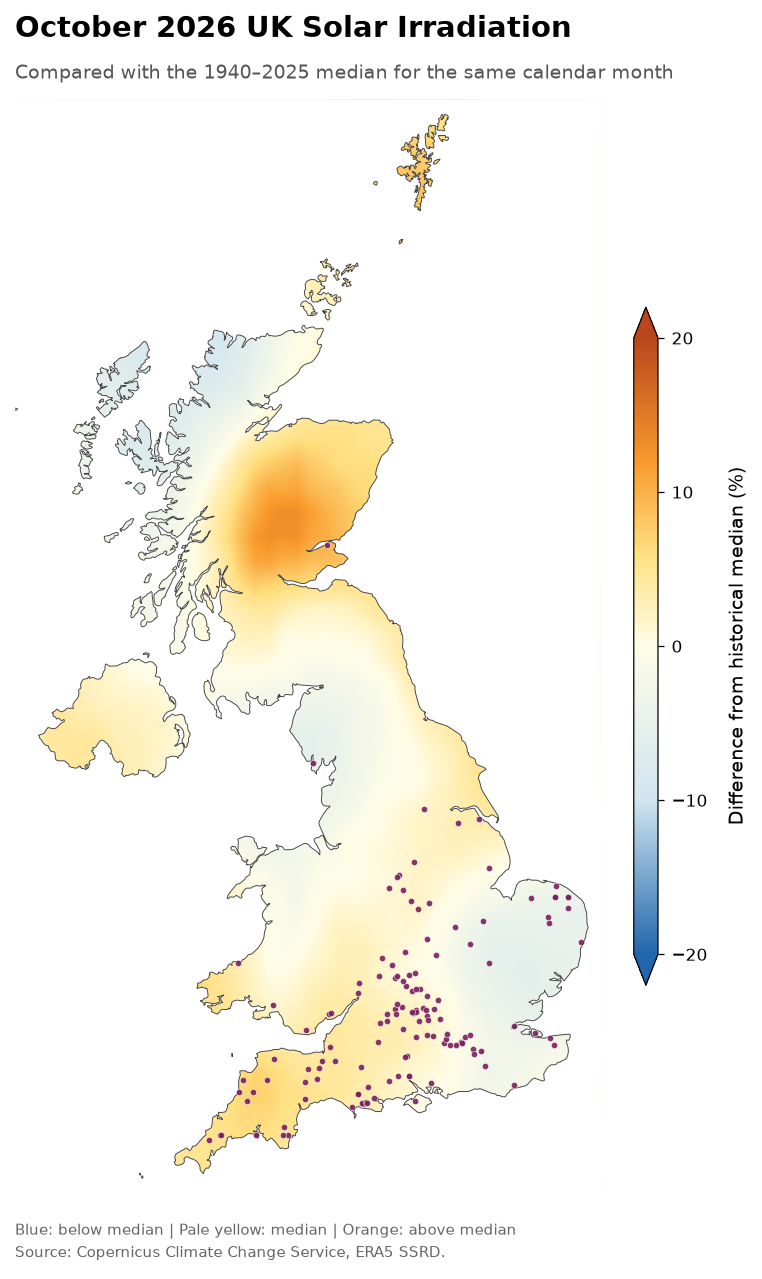

In [96]:
import matplotlib.pyplot as plt
import geopandas as gpd
from matplotlib.colors import LinearSegmentedColormap
from shapely.geometry import box
from shapely.ops import unary_union

# Prepare the coastline and white sea overlay
land = uk_boundary.to_crs("EPSG:4326")
sea = box(
    UK_BOUNDS["west"], UK_BOUNDS["south"],
    UK_BOUNDS["east"], UK_BOUNDS["north"],
).difference(unary_union(land.geometry))

# Comparison colours: blue below median, yellow at median, orange above
comparison_cmap = LinearSegmentedColormap.from_list(
    "irradiation_comparison",
    [
        (0.00, "#2166ac"),
        (0.25, "#d1e5f0"),
        (0.50, "#fffde7"),
        (0.65, "#ffe082"),
        (0.80, "#f99a2c"),
        (1.00, "#b9471c"),
    ],
    N=256,
)
comparison_cmap.set_bad("#dddddd")

# Plot the irradiation comparison
fig, ax = plt.subplots(figsize=(7.2, 9), dpi=150, facecolor="white")

image = percentage_difference.transpose("latitude", "longitude").plot.imshow(
    ax=ax,
    x="longitude",
    y="latitude",
    cmap=comparison_cmap,
    vmin=-20,
    vmax=20,
    interpolation="bilinear",
    add_colorbar=False,
    add_labels=False,
    zorder=1,
)

# Cover the sea, then draw the coastline and solar sites
gpd.GeoSeries([sea], crs="EPSG:4326").plot(
    ax=ax, facecolor="white", edgecolor="none",
    linewidth=0, aspect=None, zorder=2,
)
land.boundary.plot(
    ax=ax, color="#444444", linewidth=0.45, zorder=3,
)
ax.scatter(
    sites["longitude"], sites["latitude"],
    s=9, color="#7a1f5c", edgecolor="white",
    linewidth=0.25, alpha=0.9, zorder=5,
)

# Trim the empty sea below the land and hide map axes
ax.set_xlim(UK_BOUNDS["west"], UK_BOUNDS["east"])
ax.set_ylim(
    max(UK_BOUNDS["south"], land.total_bounds[1] - 0.15),
    UK_BOUNDS["north"],
)
ax.set_axis_off()

# Title and subtitle
month_label = selected_month.valid_time.dt.strftime("%B %Y").values[0]
ax.set_title(
    f"{month_label} UK Solar Irradiation",
    fontsize=14, fontweight="semibold", loc="left", pad=30,
)
ax.text(
    0, 1.015,
    f"Compared with the {BASELINE_START}–{BASELINE_END} "
    "median for the same calendar month",
    transform=ax.transAxes,
    fontsize=9, color="#555555", va="bottom",
)

# Colour bar
colourbar = fig.colorbar(
    image, ax=ax, shrink=0.62, aspect=28, pad=0.035,
    ticks=[-20, -10, 0, 10, 20], extend="both",
)
colourbar.set_label(
    "Difference from historical median (%)",
    fontsize=9, labelpad=10,
)
colourbar.ax.tick_params(labelsize=8, length=3, width=0.6)
colourbar.outline.set_linewidth(0.6)

# Key and source directly beneath the map
ax.text(
    0, -0.025,
    "Blue: below median | Pale yellow: median | Orange: above median\n"
    "Source: Copernicus Climate Change Service, ERA5 SSRD.",
    transform=ax.transAxes,
    fontsize=7, color="#666666",
    ha="left", va="top", linespacing=1.5, clip_on=False,
)

fig.subplots_adjust(left=0.03, right=0.90, top=0.90, bottom=0.09)
plt.show()
 

In [97]:
#checking actual ranges
print(
    f"Lowest difference: "
    f"{percentage_difference.min(skipna=True).item():.1f}%"
)

print(
    f"Highest difference: "
    f"{percentage_difference.max(skipna=True).item():.1f}%"
)

Lowest difference: -12.0%
Highest difference: 13.2%


seeing just long term average daily irradiation with all data

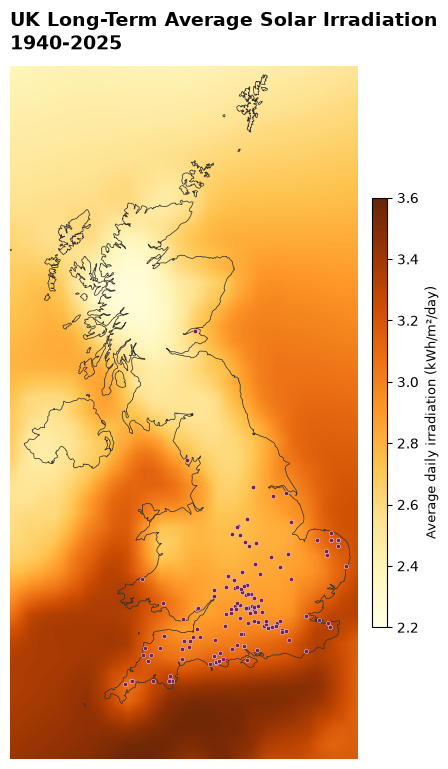

In [92]:
# Long-term average daily irradiation, 1940-2025

# Convert ERA5 SSRD from J/m²/day to kWh/m²/day
historical_kwh = historical / 3_600_000

# Weight each monthly value by the number of days in that month
days_in_month = historical.valid_time.dt.days_in_month

historical_average_map = historical_kwh.weighted(
    days_in_month
).mean(dim="valid_time")

# Plot
fig, ax = plt.subplots(figsize=(7.2, 9))

image = historical_average_map.transpose(
    "latitude", "longitude"
).plot.imshow(
    ax=ax,
    x="longitude",
    y="latitude",
    cmap="YlOrBr",
    vmin=2.2,
    vmax=3.6,
    interpolation="bilinear",
    add_colorbar=False,
    add_labels=False,
)

# UK boundary
uk_boundary.to_crs("EPSG:4326").boundary.plot(
    ax=ax,
    color="#333333",
    linewidth=0.55,
)

# Solar sites
ax.scatter(
    sites["longitude"],
    sites["latitude"],
    s=10,
    color="#7a1f5c",
    edgecolor="white",
    linewidth=0.3,
    zorder=5,
)

ax.set_xlim(UK_BOUNDS["west"], UK_BOUNDS["east"])
ax.set_ylim(UK_BOUNDS["south"], UK_BOUNDS["north"])
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")

for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_title(
    f"UK Long-Term Average Solar Irradiation\n"
    f"{BASELINE_START}-{BASELINE_END}",
    fontsize=14,
    fontweight="semibold",
    loc="left",
    pad=12,
)

colourbar = fig.colorbar(
    image,
    ax=ax,
    shrink=0.62,
    aspect=28,
    pad=0.025,
)

colourbar.set_label(
    "Average daily irradiation (kWh/m²/day)",
    fontsize=9,
)

plt.show()

In [91]:
print(f"Minimum: {float(historical_average_map.min()):.2f}")
print(f"Maximum: {float(historical_average_map.max()):.2f}")

Minimum: 2.25
Maximum: 3.58
